<a href="https://colab.research.google.com/github/mirandaurban/tc3009c/blob/main/Cloud/CCBD_Classwork_04_Spark_Exploratory_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CCBD Classwork 04: Spark Exploratory Data Analysis

### Imports

In [5]:
from google.colab import files
from pyspark import SparkContext, SparkConf,SQLContext
from pyspark.sql import SparkSession
from pyspark.sql.functions import isnan, when, count, col, lit
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [30]:
#Small printing
%precision 2
np.set_printoptions(precision=2)

### Crear contexto Spark y SQL Contexts

In [7]:
# create sparksession and sparkcontext
sc = SparkContext.getOrCreate(SparkConf().setMaster("local[*]"))

spark = SparkSession \
    .builder \
    .getOrCreate()

sqlContext = SQLContext(sc)

### Importar Google Drive

In [31]:
#Mount Google drive, read local file. The file was previously uploaded to Google Drive
from google.colab import drive
drive.mount("/content/drive")
%ls

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
drive/  sample_data/


## Spotify

Se usará el dataset `SpotifyTop2018_40_V2.csv` con la lista de las 40 canciones más populares de 2018 para analizar los datos y poder realizar posibles sugerencias.

In [77]:
# @title Importar el dataset

path_csv="drive/My Drive/Colab Notebooks/cn/spotify.csv"
df_spotify = sqlContext.read.csv(path_csv,header=True,inferSchema=True)
df_spotify.show(10)

+--------------------+------------+------+--------+-----------+------------+----------------+--------+-------+-------+-----------+--------------+
|                 _c0|danceability|energy|loudness|speechiness|acousticness|instrumentalness|liveness|valence|  tempo|duration_ms|time_signature|
+--------------------+------------+------+--------+-----------+------------+----------------+--------+-------+-------+-----------+--------------+
|                Dura|       0.791| 0.848|  -3.456|     0.0506|       0.183|             0.0|   0.409|  0.828|   95.0|     200480|             4|
|           Plug_Walk|       0.876| 0.519|  -6.531|      0.143|       0.202|             0.0|   0.108|  0.158| 94.981|     175230|             4|
|             Silence|        0.52| 0.761|  -3.093|     0.0853|       0.256|         4.96E-6|    0.17|  0.286|141.971|     180823|             4|
|Solo_(feat._Demi_...|       0.737| 0.636|  -4.546|     0.0437|      0.0441|         6.66E-5|    0.35|  0.565|105.005|     2

In [78]:
# @title Numeric summary

df_spotify.describe().show()

+-------+--------------------+-------------------+-------------------+------------------+-------------------+------------------+--------------------+-------------------+-------------------+------------------+-----------------+------------------+
|summary|                 _c0|       danceability|             energy|          loudness|        speechiness|      acousticness|    instrumentalness|           liveness|            valence|             tempo|      duration_ms|    time_signature|
+-------+--------------------+-------------------+-------------------+------------------+-------------------+------------------+--------------------+-------------------+-------------------+------------------+-----------------+------------------+
|  count|                  40|                 40|                 40|                40|                 40|                40|                  40|                 40|                 40|                40|               40|                40|
|   mean|       

In [79]:
df_spotify.describe().toPandas().transpose()

,0,1,2,3,4
summary,count,mean,stddev,min,max
_c0,40,None,None,Believer,no_tears_left_to_cry
danceability,40,0.7192000000000001,0.15142285841735406,0.258,0.922
energy,40,0.661925,0.13787366709028623,0.391,0.909
loudness,40,-5.84625,1.6110514921182404,-9.211,-3.093
speechiness,40,0.12129249999999998,0.09473181413323806,0.0232,0.516
acousticness,40,0.1846213,0.2090523279895644,2.82E-4,0.847
instrumentalness,40,0.00369513875,0.021230659055011928,0.0,0.134
liveness,40,0.17712499999999998,0.13047597430866295,0.0215,0.552
valence,40,0.46794249999999993,0.22850374837019802,0.0967,0.931


In [80]:
# @title Correlación

from pyspark.mllib.stat import Statistics

# Drop the non-numeric columns like '_c0' (song names)
df_features = df_spotify.drop("_c0")

# select variables to check correlation
df_features = df_features.dropna()

# Usar el DataFrame limpio que solo contiene columnas numéricas
rdd_table = df_features.rdd.map(lambda row: row[0:])

# Calcular la matriz de correlación
corr_mat = Statistics.corr(rdd_table, method="pearson")
corr_mat_pd = pd.DataFrame(data=corr_mat, index=df_features.columns, columns=df_features.columns)
corr_mat_pd

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,time_signature
danceability,1.000000,-0.052973,-0.043320,0.207397,0.016291,-0.102198,-0.031392,0.470648,-0.301067,-0.305303,0.268821
energy,-0.052973,1.000000,0.665634,-0.035225,-0.269420,0.159487,-0.082066,0.465742,0.005003,-0.035215,0.234110
loudness,-0.043320,0.665634,1.000000,-0.281621,-0.081194,0.079780,-0.050145,0.402273,-0.034438,0.011911,-0.032557
speechiness,0.207397,-0.035225,-0.281621,1.000000,0.097140,-0.131971,-0.225592,0.059612,0.018453,-0.144740,0.224884
acousticness,0.016291,-0.269420,-0.081194,0.097140,1.000000,-0.150742,-0.155930,0.174967,-0.064332,-0.297226,-0.006534
instrumentalness,-0.102198,0.159487,0.079780,-0.131971,-0.150742,1.000000,-0.046094,-0.130534,0.254822,-0.072171,0.040438
liveness,-0.031392,-0.082066,-0.050145,-0.225592,-0.155930,-0.046094,1.000000,-0.108392,-0.281270,-0.115850,-0.090593
valence,0.470648,0.465742,0.402273,0.059612,0.174967,-0.130534,-0.108392,1.000000,-0.240702,-0.273304,0.302942
tempo,-0.301067,0.005003,-0.034438,0.018453,-0.064332,0.254822,-0.281270,-0.240702,1.000000,-0.174676,0.056347
duration_ms,-0.305303,-0.035215,0.011911,-0.144740,-0.297226,-0.072171,-0.115850,-0.273304,-0.174676,1.000000,-0.272389


In [22]:
!pip install heatmapz

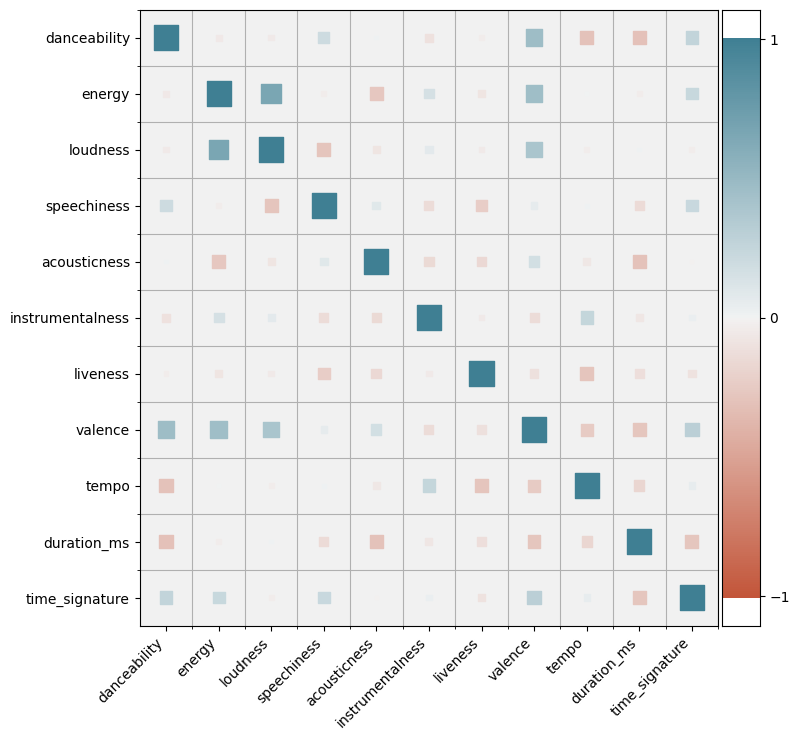

In [81]:
from pyspark.ml.stat import Correlation
from pyspark.ml.feature import VectorAssembler
import plotly.express as px
from heatmap import corrplot

# convert to vector column first
vector_col = "corr_features"
assembler = VectorAssembler(inputCols=df_features.columns, outputCol=vector_col)
df_vector = assembler.transform(df_features).select(vector_col)

# get correlation matrix
r1 = Correlation.corr(df_vector, vector_col)
num_vars = len(df_features.columns)

pearson_corr_arr = np.matrix(r1.collect()[0]["pearson({})".format(vector_col)].values).reshape(num_vars, num_vars)
pearson_corr_pd = pd.DataFrame(data=pearson_corr_arr, index=df_features.columns, columns=df_features.columns)

plt.figure(figsize=(8, 8))
corrplot(pearson_corr_pd, size_scale=300);

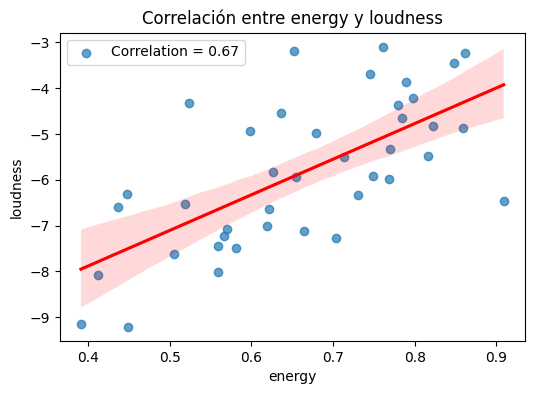

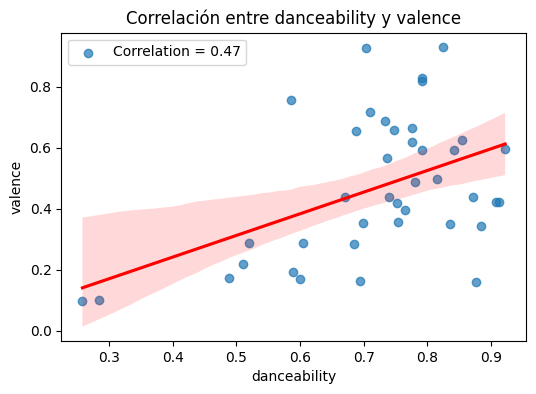

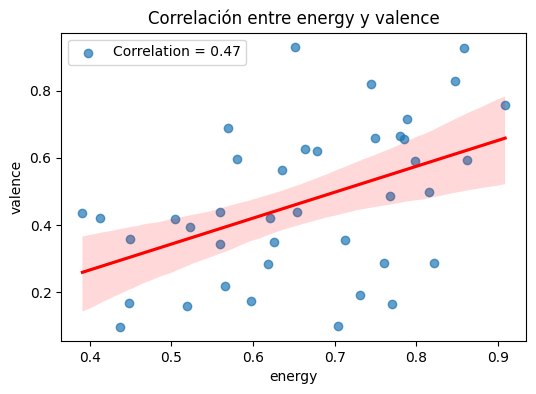

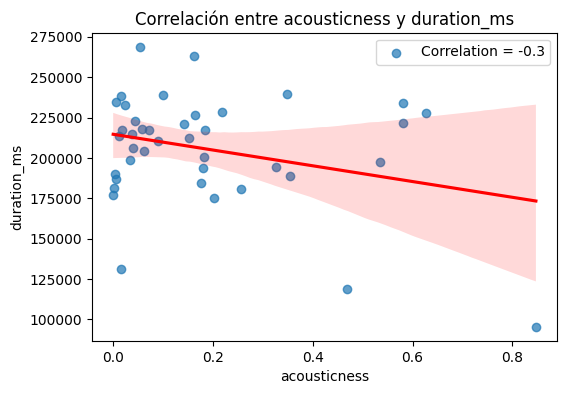

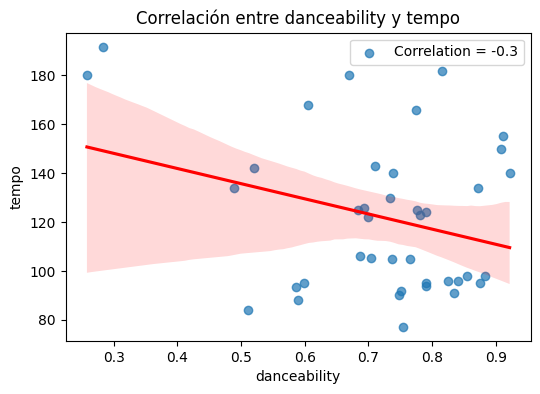

In [27]:
# @title Scatterplots para los pares de variables con línea de tendencia y coeficiente de correlación
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Convert the Spark DataFrame to a Pandas DataFrame first
pdf = df_spotify.toPandas()

def plot_with_correlation(df, col1, col2):
    plt.figure(figsize=(6, 4))
    c1 = df[col1]
    c2 = df[col2]
    corr_coef = np.round(np.corrcoef(c1, c2)[0, 1], 2)

    # Use regplot to show the scatter points along with the correlation line
    sns.regplot(
        data=df,
        x=col1,
        y=col2,
        label=f'Correlation = {corr_coef}',
        scatter_kws={'alpha':0.7},
        line_kws={'color':'red'}
    )

    plt.title(f'Correlación entre {col1} y {col2}')
    plt.xlabel(col1)
    plt.ylabel(col2)
    plt.legend()
    plt.show()

# Generar gráficos
plot_with_correlation(pdf, 'energy', 'loudness')
plot_with_correlation(pdf, 'danceability', 'valence')
plot_with_correlation(pdf, 'energy', 'valence')
plot_with_correlation(pdf, 'acousticness', 'duration_ms')
plot_with_correlation(pdf, 'danceability', 'tempo')

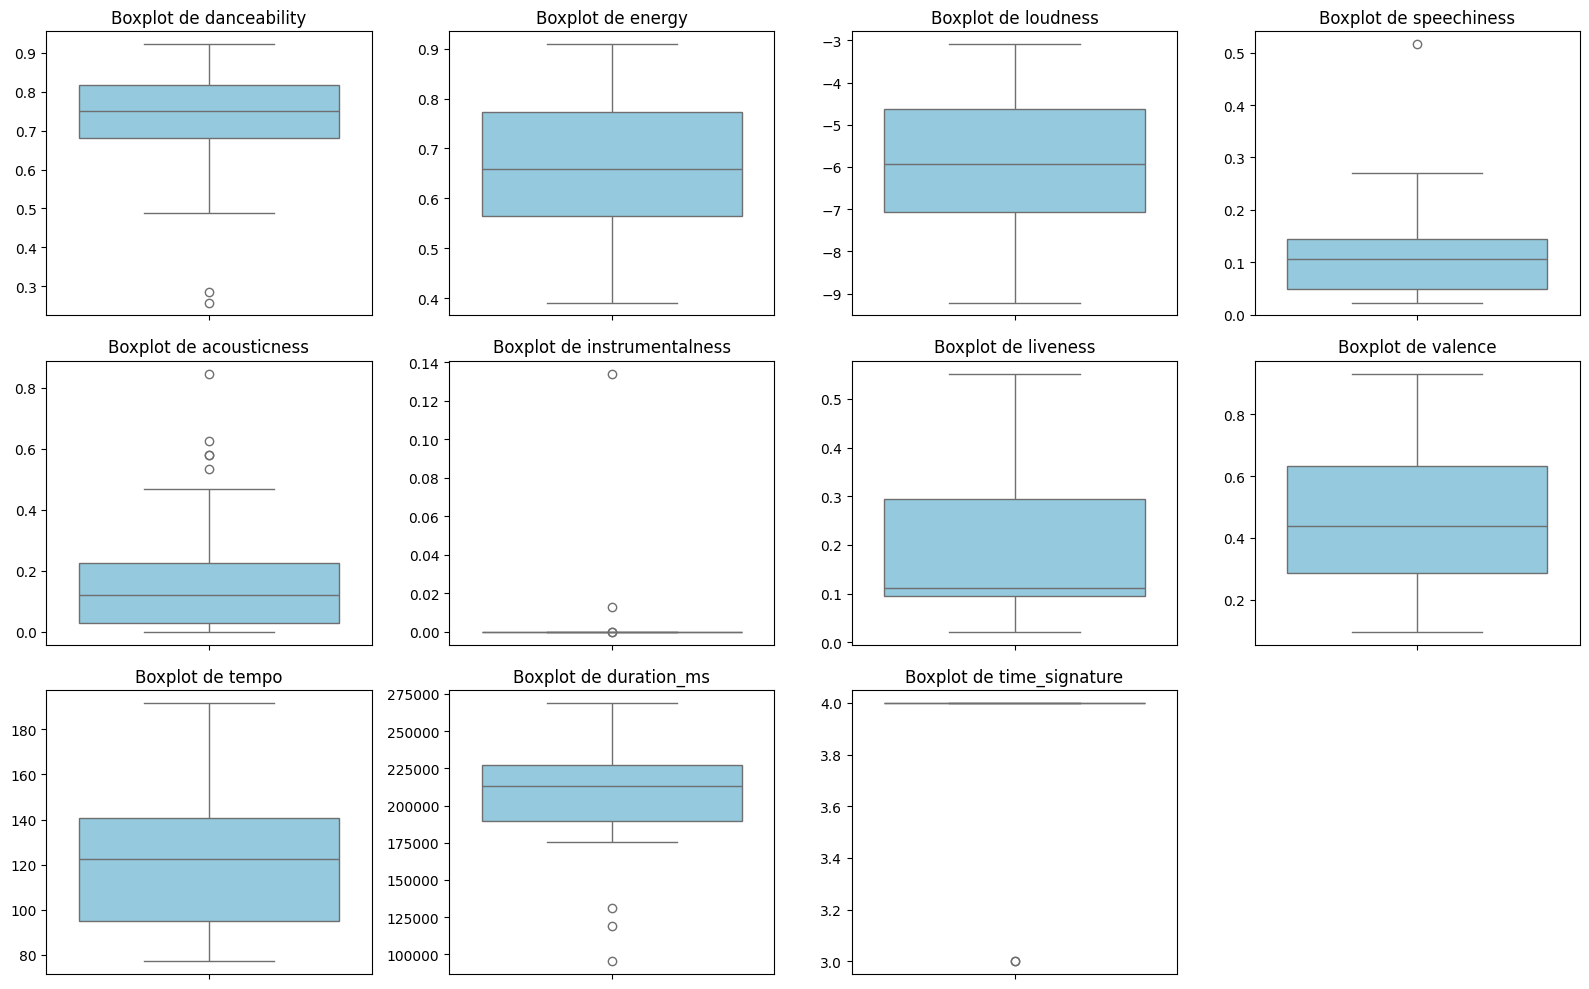


Valores Atípicos Detectados (Método IQR):

Variable: danceability (Límite Inferior: 0.475, Límite Superior: 1.023)


,_c0,danceability
22,Dusk_Till_Dawn_-_Radio_Edit,0.258
24,This_Is_Me,0.284


--------------------------------------------------
Variable: speechiness (Límite Inferior: -0.093, Límite Superior: 0.287)


,_c0,speechiness
7,River_(feat._Ed_Sheeran),0.516


--------------------------------------------------
Variable: acousticness (Límite Inferior: -0.264, Límite Superior: 0.523)


,_c0,acousticness
14,Psycho_(feat._Ty_Dolla_$ign),0.580
16,Everybody_Dies_In_Their_Nightmares,0.847
23,Candy_Paint,0.627
26,I_Like_Me_Better,0.535
29,Shape_of_You,0.581


... (3 outputs left out)

,_c0,duration_ms
16,Everybody_Dies_In_Their_Nightmares,95467
17,Jocelyn_Flores,119133
35,Mine,131064


--------------------------------------------------
Variable: time_signature (Límite Inferior: 4.000, Límite Superior: 4.000)


,_c0,time_signature
5,Call_Out_My_Name,3
12,Perfect,3


--------------------------------------------------


In [29]:
# @title Box plots y valores atípicos
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

numerical_cols = [col for col in pdf.columns if col != '_c0']

# Box Plots
plt.figure(figsize=(16, 10))
for i, col_name in enumerate(numerical_cols, 1):
    plt.subplot(3, 4, i)
    sns.boxplot(data=pdf, y=col_name, color='skyblue')
    plt.title(f'Boxplot de {col_name}')
    plt.ylabel('')
plt.tight_layout()
plt.show()

# Outliers usando el método IQR
print(f"\nValores Atípicos Detectados (Método IQR):\n")
outliers_found = False

for col_name in numerical_cols:
    q1 = pdf[col_name].quantile(0.25)
    q3 = pdf[col_name].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    # Filtrar outliers
    outliers = pdf[(pdf[col_name] < lower_bound) | (pdf[col_name] > upper_bound)]

    if not outliers.empty:
        outliers_found = True
        print(f"Variable: {col_name} (Límite Inferior: {lower_bound:.3f}, Límite Superior: {upper_bound:.3f})")
        display(outliers[['_c0', col_name]])
        print("-" * 50)

if not outliers_found:
    print("No se detectaron valores atípicos en ninguna variable.")

### Conclusiones

Las asociaciones más relevantes entre las variables son:

1. **Energy y loudness:** Presentan una correlación positiva fuerte. Las canciones con mayor energía tienden a tener un volumen más elevado.
2. **Danceability y valence:** Muestran una correlación positiva. Las canciones más bailables tienden a tener una valencia más alta, asociada con un estado de ánimo más positivo.
3. **Energy y valence:** Presentan una correlación positiva, lo que sugiere que las canciones con mayor energía tienden a transmitir emociones más positivas.
4. **Acousticness y duration_ms:** Muestran una correlación negativa, indicando que, a mayor nivel de acústica, tiende a disminuir la duración de las canciones.
5. **Danceability y tempo:** Presentan una correlación negativa, aunque relativamente débil.

En conclusión, **Energy y loudness** presentan la asociación positiva más destacada, mientras que las demás relaciones son considerablemente más débiles.

## Titanic

Se usará el dataset `titanicV2020.csv` para analizarlo y determinar la utilidad de ciertas variables.

In [41]:
# @title Importar el dataset

path_csv="drive/My Drive/Colab Notebooks/cn/titanic.csv"
df_titanic = sqlContext.read.csv(path_csv,header=True,inferSchema=True)
df_titanic.show(10)

+-----------+--------+------+--------------------+------+---+-----+-----+----------------+-------+-----+--------+
|PassengerId|Survived|Pclass|                Name|   Sex|Age|SibSp|Parch|          Ticket|   Fare|Cabin|Embarked|
+-----------+--------+------+--------------------+------+---+-----+-----+----------------+-------+-----+--------+
|          1|       0|     3|Braund, Mr. Owen ...|  male| 22|    1|    0|       A/5 21171|   7.25|   NA|       S|
|          2|       1|     1|Cumings, Mrs. Joh...|female| 38|    1|    0|        PC 17599|71.2833|  C85|       C|
|          3|       1|     3|Heikkinen, Miss. ...|female| 26|    0|    0|STON/O2. 3101282|  7.925|   NA|       S|
|          4|       1|     1|Futrelle, Mrs. Ja...|female| 35|    1|    0|          113803|   53.1| C123|       S|
|          5|       0|     3|Allen, Mr. Willia...|  male| 35|    0|    0|          373450|   8.05|   NA|       S|
|          6|       0|     3|    Moran, Mr. James|  male| NA|    0|    0|          33087

In [65]:
# @title Entendimiento de los datos

# Dimensiones del dataset originales
print("Dimensiones originales del dataset:", (df_titanic.count(), len(df_titanic.columns)))

df_titanic.describe().toPandas().transpose()

Dimensiones originales del dataset: (1309, 12)


,0,1,2,3,4
summary,count,mean,stddev,min,max
PassengerId,1309,655.0,378.0200611960517,1,1309
Survived,1309,0.37738731856378915,0.48491831071362734,0,1
Pclass,1309,2.294881588999236,0.8378360189701276,1,3
Name,1309,None,None,"Abbing, Mr. Anthony","van Melkebeke, Mr. Philemon"
Sex,1309,None,None,female,male
Age,1309,29.881137667304014,14.413493211271321,0.17,NA
SibSp,1309,0.4988540870893812,1.0416583905961028,0,8
Parch,1309,0.3850267379679144,0.8655602753495157,0,9
Ticket,1309,249039.1368861024,442685.31767656445,110152,WE/P 5735


In [68]:
# @title Limpieza de los datos
from pyspark.sql.types import NumericType, DoubleType
from pyspark.ml.feature import Imputer
from pyspark.ml.feature import StringIndexer

# Seleccionar las columnas iniciales
data = df_titanic.select(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare'])

# Reemplazar caracteres 'NA' por None y convertir las columnas de string a DoubleType antes de imputar
data = data.withColumn("Age", when(col("Age") == "NA", None).otherwise(col("Age")).cast(DoubleType()))
data = data.withColumn("Fare", when(col("Fare") == "NA", None).otherwise(col("Fare")).cast(DoubleType()))

# Rellenar valores NA en la columna de edad usando Imputer
imputer = Imputer(strategy='mean', inputCols=['Age'], outputCols=['AgeImputed'])
imputer_model = imputer.fit(data)
data = imputer_model.transform(data)

# Eliminar filas con NAs que aún queden en otras columnas críticas
data = data.dropna()

# Indexación de la variable género (Sex)
gender_indexer = StringIndexer(inputCol='Sex', outputCol='SexIndexed')
gender_indexer_model = gender_indexer.fit(data)
data = gender_indexer_model.transform(data)

# Dimensiones del dataset resultante
print("Dimensiones actuales del dataset:", (data.count(), len(data.columns)))

Dimensiones actuales del dataset: (1045, 9)


In [69]:
# @ Numeric summary

data.describe().show()

+-------+-------------------+------------------+------+------------------+------------------+-------------------+-----------------+------------------+-------------------+
|summary|           Survived|            Pclass|   Sex|               Age|             SibSp|              Parch|             Fare|        AgeImputed|         SexIndexed|
+-------+-------------------+------------------+------+------------------+------------------+-------------------+-----------------+------------------+-------------------+
|  count|               1045|              1045|  1045|              1045|              1045|               1045|             1045|              1045|               1045|
|   mean| 0.3990430622009569|2.2066985645933013|  NULL|29.851837320574163|0.5033492822966508|0.42105263157894735| 36.6860802870813|29.851837320574163| 0.3712918660287081|
| stddev|0.48993611580404817|0.8415418196058035|  NULL|14.389194476891909|0.9124712127469656|  0.840051564113195|55.73253318137738|14.38919447689

In [70]:
data.describe().toPandas().transpose()

,0,1,2,3,4
summary,count,mean,stddev,min,max
Survived,1045,0.3990430622009569,0.48993611580404817,0,1
Pclass,1045,2.2066985645933013,0.8415418196058035,1,3
Sex,1045,None,None,female,male
Age,1045,29.851837320574163,14.389194476891909,0.17,80.0
SibSp,1045,0.5033492822966508,0.9124712127469656,0,8
Parch,1045,0.42105263157894735,0.840051564113195,0,6
Fare,1045,36.6860802870813,55.73253318137738,0.0,512.3292
AgeImputed,1045,29.851837320574163,14.389194476891909,0.17,80.0
SexIndexed,1045,0.3712918660287081,0.48338164243401366,0.0,1.0


In [72]:
# @title Correlación

from pyspark.mllib.stat import Statistics

# Seleccionar solo las columnas estrictamente numéricas (excluyendo 'Sex' de tipo texto)
columnas_numericas = ['Survived', 'Pclass', 'AgeImputed', 'SibSp', 'Parch', 'Fare', 'SexIndexed']
data_numeric = data.select(columnas_numericas)

# Usar el DataFrame limpio que solo contiene columnas numéricas
rdd_table = data_numeric.rdd.map(lambda row: row[0:])

# Calcular la matriz de correlación
corr_mat = Statistics.corr(rdd_table, method="pearson")
corr_mat_pd = pd.DataFrame(data=corr_mat, index=data_numeric.columns, columns=data_numeric.columns)
corr_mat_pd

,Survived,Pclass,AgeImputed,SibSp,Parch,Fare,SexIndexed
Survived,1.000000,-0.281555,-0.052168,0.010934,0.115018,0.239842,0.684221
Pclass,-0.281555,1.000000,-0.411086,0.047746,0.017685,-0.565255,-0.144105
AgeImputed,-0.052168,-0.411086,1.000000,-0.243139,-0.150241,0.178740,-0.062235
SibSp,0.010934,0.047746,-0.243139,1.000000,0.374291,0.141184,0.094902
Parch,0.115018,0.017685,-0.150241,0.374291,1.000000,0.216723,0.220864
Fare,0.239842,-0.565255,0.178740,0.141184,0.216723,1.000000,0.187930
SexIndexed,0.684221,-0.144105,-0.062235,0.094902,0.220864,0.187930,1.000000


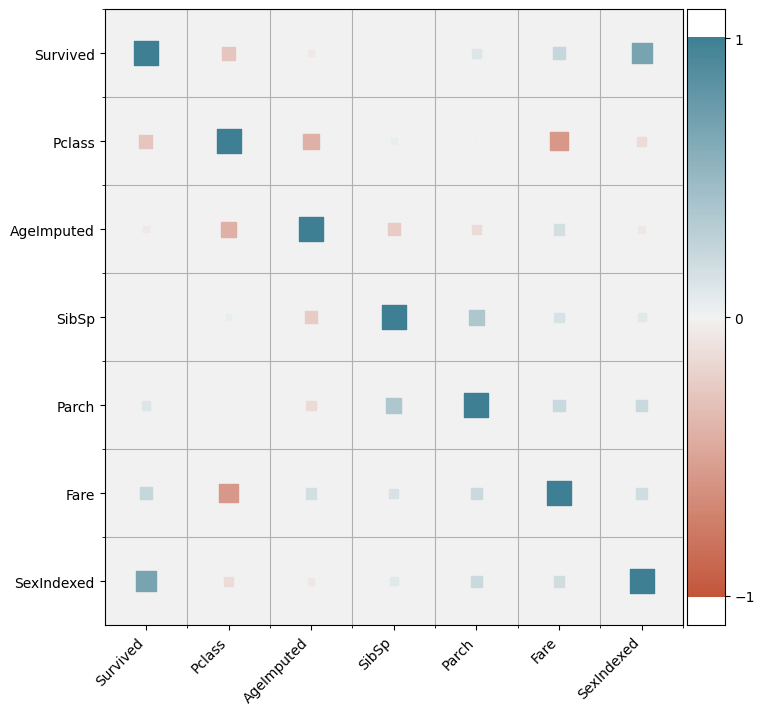

In [73]:
from pyspark.ml.stat import Correlation
from pyspark.ml.feature import VectorAssembler
import plotly.express as px
from heatmap import corrplot

# convert to vector column first
vector_col = "corr_features"
assembler = VectorAssembler(inputCols=data_numeric.columns, outputCol=vector_col)
df_vector = assembler.transform(data_numeric).select(vector_col)

# get correlation matrix
r1 = Correlation.corr(df_vector, vector_col)
num_vars = len(data_numeric.columns)

pearson_corr_arr = np.matrix(r1.collect()[0]["pearson({})".format(vector_col)].values).reshape(num_vars, num_vars)
pearson_corr_pd = pd.DataFrame(data=pearson_corr_arr, index=data_numeric.columns, columns=data_numeric.columns)

plt.figure(figsize=(8, 8))
corrplot(pearson_corr_pd, size_scale=300);

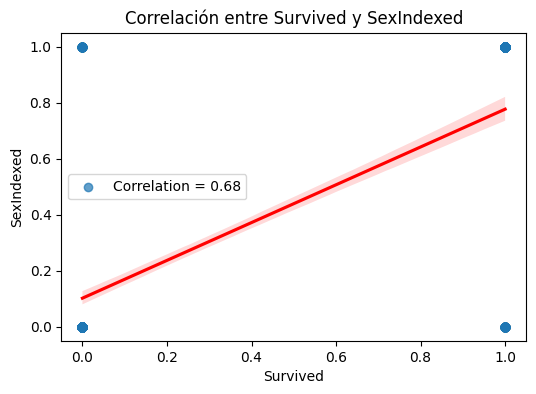

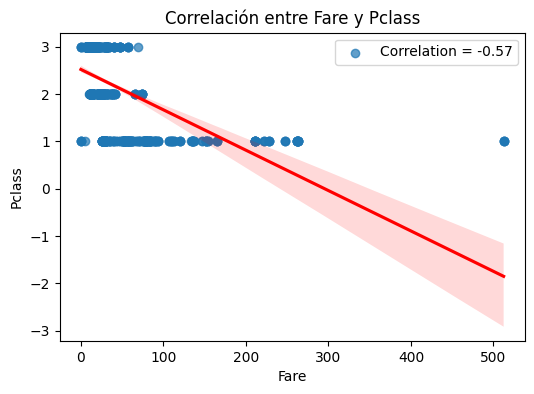

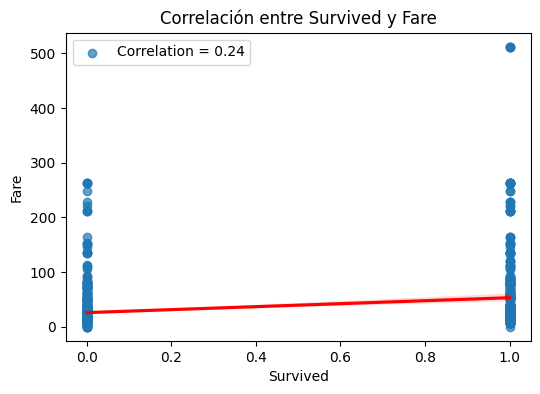

In [82]:
# @title Scatterplots para los pares de variables con línea de tendencia y coeficiente de correlación
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

pdf = data_numeric.toPandas()

def plot_with_correlation(df, col1, col2):
    plt.figure(figsize=(6, 4))
    c1 = df[col1]
    c2 = df[col2]
    corr_coef = np.round(np.corrcoef(c1, c2)[0, 1], 2)

    # Use regplot to show the scatter points along with the correlation line
    sns.regplot(
        data=df,
        x=col1,
        y=col2,
        label=f'Correlation = {corr_coef}',
        scatter_kws={'alpha':0.7},
        line_kws={'color':'red'}
    )

    plt.title(f'Correlación entre {col1} y {col2}')
    plt.xlabel(col1)
    plt.ylabel(col2)
    plt.legend()
    plt.show()

# Generar gráficos
plot_with_correlation(pdf, 'Survived', 'SexIndexed')
plot_with_correlation(pdf, 'Fare', 'Pclass')
plot_with_correlation(pdf, 'Survived', 'Fare')

### Conclusiones

Las variables que presentan mayor asociación con la supervivencia (*Survived*) son:

- **SexIndexed:** Presenta una correlación positiva relativamente fuerte con la supervivencia, lo que indica que el sexo fue una de las variables más relacionadas con la probabilidad de sobrevivir.
- **Pclass:** Muestra una correlación negativa. Esto sugiere que los pasajeros de clases sociales más altas (primera clase) tuvieron mayores probabilidades de supervivencia.
- **Fare:** Presenta una correlación positiva, indicando que los pasajeros que pagaron tarifas más elevadas tendieron a tener mayores probabilidades de sobrevivir.

En conclusión, **SexIndexed y Pclass** son las variables con asociaciones más relevantes respecto a la supervivencia, seguidas de Fare. Esto sugiere que tanto el sexo como la posición socioeconómica influyeron en las probabilidades de sobrevivir al naufragio.

Las demás variables, como AgeImputed, SibSp y Parch, presentan correlaciones débiles con la supervivencia.